# Phase 6: Customer Demand Prediction
This notebook builds and compares predictive ML models (Linear Regression vs. Random Forest Regressor) to estimate expected hourly demand for shops.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pickle
import os

sns.set_theme(style="whitegrid")
os.makedirs('../models', exist_ok=True)
print("Libraries loaded.")

Libraries loaded.


## 1. Load Data and Aggregate to Hourly Demand
We aggregate visits into shop-date-hour count to form the target variable `customer_count`.

In [2]:
visits = pd.read_csv('../data/processed/visits.csv')
shops = pd.read_csv('../data/processed/shops.csv')

# Extract hour and day features
visits['arrival_datetime'] = pd.to_datetime(visits['date'] + ' ' + visits['arrival_time'])
visits['hour'] = visits['arrival_datetime'].dt.hour
visits['day_of_week'] = visits['arrival_datetime'].dt.dayofweek
visits['month'] = visits['arrival_datetime'].dt.month

# Group by shop, date, hour to get client counts (demand)
demand = visits.groupby(['shop_id', 'date', 'hour']).size().reset_index(name='customer_count')

# Pivot/fill missing combinations with 0 to represent 0 demand hours
# Let's generate a full index of shops, dates, and hours (e.g. from 8 AM to 8 PM)
all_shops = shops['shop_id'].unique()
all_dates = visits['date'].unique()
all_hours = np.arange(8, 21) # 8 AM to 8 PM

index = pd.MultiIndex.from_product([all_shops, all_dates, all_hours], names=['shop_id', 'date', 'hour'])
full_df = pd.DataFrame(index=index).reset_index()

demand = pd.merge(full_df, demand, on=['shop_id', 'date', 'hour'], how='left').fillna(0)
demand['customer_count'] = demand['customer_count'].astype(int)
print(f"Total rows in aggregated demand matrix: {len(demand)}")

Total rows in aggregated demand matrix: 59150


## 2. Feature Engineering
Merge shop metadata and time-based features.

In [3]:
demand = demand.merge(shops[['shop_id', 'rating', 'number_of_seats', 'number_of_barbers', 'shop_type']], on='shop_id')

demand['date'] = pd.to_datetime(demand['date'])
demand['day_of_week'] = demand['date'].dt.dayofweek
demand['weekend_flag'] = (demand['day_of_week'] >= 4).astype(int) # Friday, Saturday, Sunday
demand['month'] = demand['date'].dt.month

# Add a simple historical demand average for each (shop_id, hour, day_of_week) as a feature
hist_demand = demand.groupby(['shop_id', 'hour', 'day_of_week'])['customer_count'].mean().reset_index(name='historical_average_demand')
demand = demand.merge(hist_demand, on=['shop_id', 'hour', 'day_of_week'], how='left')

# Drop non-feature columns
X_cols = ['hour', 'day_of_week', 'weekend_flag', 'month', 'rating', 'number_of_seats', 'number_of_barbers', 'historical_average_demand']
X = demand[X_cols]
y = demand['customer_count']

# Categorical conversion if any (shop_type is ignored for now to keep features simple)
print("Features prepared.")

Features prepared.


## 3. Time-Based Train/Test Split
To avoid data leakage, we split training and testing by date (first 75 days for train, last 15 days for test).

In [4]:
# Date threshold split
unique_dates = sorted(demand['date'].unique())
split_idx = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_idx]

train_mask = demand['date'] < split_date
test_mask = demand['date'] >= split_date

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")
print(f"Split date threshold: {split_date}")

Train size: 46800, Test size: 12350
Split date threshold: 2026-08-12 00:00:00


## 4. Train Models & Compare

In [5]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_preds = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

# Metrics
print("Linear Regression:")
print(f" - MAE: {mean_absolute_error(y_test, lr_preds):.3f}")
print(f" - RMSE: {np.sqrt(mean_squared_error(y_test, lr_preds)):.3f}")
print(f" - R2: {r2_score(y_test, lr_preds):.3f}")

print("\nRandom Forest:")
print(f" - MAE: {mean_absolute_error(y_test, rf_preds):.3f}")
print(f" - RMSE: {np.sqrt(mean_squared_error(y_test, rf_preds)):.3f}")
print(f" - R2: {r2_score(y_test, rf_preds):.3f}")

Linear Regression:
 - MAE: 0.698
 - RMSE: 1.018
 - R2: 0.579

Random Forest:
 - MAE: 0.722
 - RMSE: 1.066
 - R2: 0.538


## 5. Feature Importance
Plotting feature importance for the Random Forest model.

C:\Users\PC\AppData\Local\Temp\ipykernel_31948\2162617988.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=[X_cols[i] for i in indices], palette="viridis")


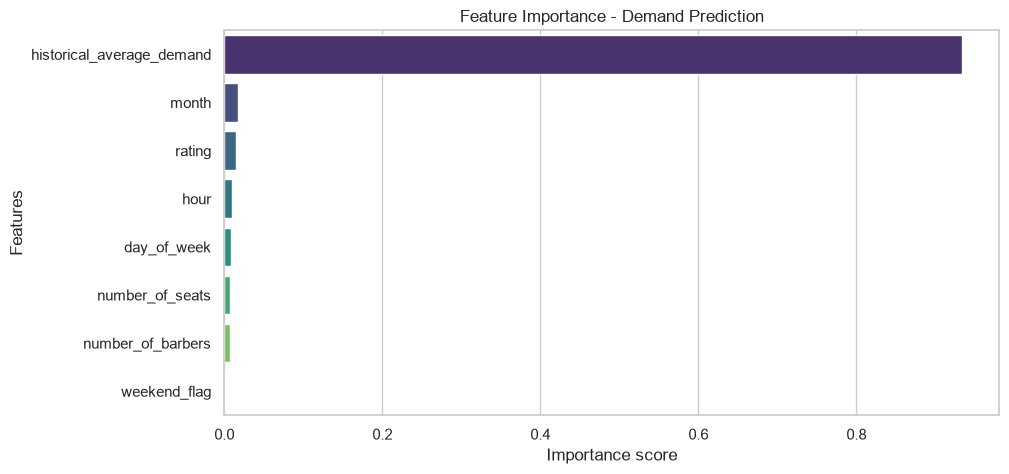

In [6]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
sns.barplot(x=importances[indices], y=[X_cols[i] for i in indices], palette="viridis")
plt.title("Feature Importance - Demand Prediction")
plt.xlabel("Importance score")
plt.ylabel("Features")
plt.savefig('../reports/figures/demand_feature_importance.png')
plt.show()

## 6. Save Model
Saving the best performing model (Random Forest) as a pickle file.

In [7]:
with open('../models/demand_model.pkl', 'wb') as f:
    pickle.dump(rf, f)
print("Saved demand_model.pkl successfully.")

Saved demand_model.pkl successfully.
